In [3]:
!pip install matplotlib
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [8]:
BATCH_SIZE = 32
IMAGE_SIZE = 256
CHANNELS = 3
EPOCHS =50

In [14]:
dataset= tf.keras.preprocessing.image_dataset_from_directory(
    "PlantVillage",
    shuffle = True,
    image_size = (IMAGE_SIZE, IMAGE_SIZE),
    batch_size =  BATCH_SIZE
)

Found 2152 files belonging to 3 classes.


In [16]:
class_names=dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

(32, 256, 256, 3)
[1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 1 2 1 0 0 0 0 1 2 0 1 0 1 1 2]


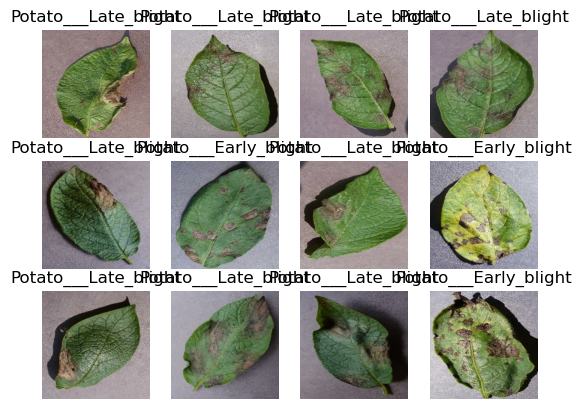

In [24]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())
    for i in range(12):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])
        plt.axis("off")

In [26]:
train_size = 0.8
len(dataset)*train_size

54.400000000000006

In [27]:
train_ds = dataset.take(54)
len(train_ds)

54

In [29]:
test_ds = dataset.skip(54)
len(test_ds)

14

In [30]:
val_size = 0.1
len(dataset)*val_size

6.800000000000001

In [32]:
val_ds = test_ds.take(6)
len(val_ds)

6

In [33]:
test_ds = test_ds.skip(6)
len(test_ds)

8

In [40]:
def data_partition(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000):
    assert(train_split+test_split+val_split) == 1

    ds_size = len(ds)
    
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
        train_size = int(train_split*ds_size)
        val_size = int(val_split * ds_size)

        train_ds = ds.take(train_size)
        val_ds = ds.skip(train_size).take(val_size)
        test_ds = ds.skip(train_size).skip(val_size)        
        
    return train_ds , val_ds, test_ds

In [41]:
train_ds , val_ds, test_ds = data_partition(dataset)

In [42]:
len(train_ds)

54

In [43]:
len(test_ds)

8

In [44]:
len(val_ds)

6

In [47]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
test_ds =  test_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
val_ds =   val_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)

In [54]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch[0].numpy()/255)

[[[0.7137255  0.72156864 0.77254903]
  [0.7372549  0.74509805 0.79607844]
  [0.74509805 0.7529412  0.8039216 ]
  ...
  [0.6039216  0.59607846 0.64705884]
  [0.5921569  0.58431375 0.63529414]
  [0.6        0.5921569  0.6431373 ]]

 [[0.69803923 0.7058824  0.75686276]
  [0.70980394 0.7176471  0.76862746]
  [0.7176471  0.7254902  0.7764706 ]
  ...
  [0.6        0.5921569  0.6431373 ]
  [0.6        0.5921569  0.6431373 ]
  [0.6117647  0.6039216  0.654902  ]]

 [[0.69411767 0.7019608  0.7529412 ]
  [0.6745098  0.68235296 0.73333335]
  [0.6627451  0.67058825 0.72156864]
  ...
  [0.58431375 0.5764706  0.627451  ]
  [0.5921569  0.58431375 0.63529414]
  [0.61960787 0.6117647  0.6627451 ]]

 ...

 [[0.79607844 0.80784315 0.84313726]
  [0.8        0.8117647  0.84705883]
  [0.8        0.8117647  0.84705883]
  ...
  [0.70980394 0.7058824  0.7372549 ]
  [0.7372549  0.73333335 0.7647059 ]
  [0.7764706  0.77254903 0.8039216 ]]

 [[0.79607844 0.80784315 0.84313726]
  [0.8        0.8117647  0.84705883]


In [57]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0 / 255)
])


In [58]:
#Here we are perforing the data augmentation

In [59]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

In [62]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    resize_and_rescale,
    data_augmentation,
    layers.Conv2D(32, kernel_size = (3,3), activation = 'relu', input_shape = input_shape),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, kernel_size = (3,3), activation = 'relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3,3) , activation = 'relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3,3) , activation = 'relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3,3) , activation = 'relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64,  activation ='relu'),
    layers.Dense(n_classes, activation = 'softmax'),
    
])

model.build(input_shape = input_shape)

In [63]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (32, 256, 256, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (32, 256, 256, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (32, 254, 254, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (32, 127, 127, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (32, 125, 125, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (32, 62, 62, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (32, 60, 60, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (32, 30, 30, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (32, 28, 28, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (32, 14, 14, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (32, 12, 12, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (32, 6, 6, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (32, 4, 4, 64)              │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (32, 2, 2, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (32, 256)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (32, 64)                    │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (32, 3)                     │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
model.compile(
    optimizer = 'adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits = False),
    metrics = ['accuracy']
)    

In [66]:
history = model.fit(
    train_ds,
    batch_size = BATCH_SIZE,
    validation_data = val_ds,
    verbose = 1,
    epochs = EPOCHS
)

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 196s 4s/step - accuracy: 0.4897 - loss: 0.9367 - val_accuracy: 0.4323 - val_loss: 0.8760
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.6314 - loss: 0.7508 - val_accuracy: 0.8177 - val_loss: 0.4739
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8206 - loss: 0.4248 - val_accuracy: 0.8750 - val_loss: 0.2728
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 145s 3s/step - accuracy: 0.9095 - loss: 0.2489 - val_accuracy: 0.9167 - val_loss: 0.2392
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 197s 4s/step - accuracy: 0.9472 - loss: 0.1490 - val_accuracy: 0.9271 - val_loss: 0.2062
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 152s 3s/step - accuracy: 0.9472 - loss: 0.1477 - val_accuracy: 0.9583 - val_loss: 0.1272
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 157s 3s/step - accuracy: 0.9735 - loss: 0.0758 - val_accuracy: 0.9167 - val_loss: 0.2328
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 177s 3s/step - accuracy: 0.9543 - loss: 0.1226 - val_accuracy: 0.9010 - va

In [67]:
len(test_ds)

8

In [68]:
scores = model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 308ms/step - accuracy: 0.9759 - loss: 0.0628


In [69]:
scores

[0.07139717042446136, 0.98046875]

In [70]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [71]:
history.history['loss']

[0.9088729023933411,
 0.7028642296791077,
 0.35677629709243774,
 0.224165141582489,
 0.1591017097234726,
 0.12885378301143646,
 0.07961822301149368,
 0.10896891355514526,
 0.12896496057510376,
 0.13198423385620117,
 0.10746680200099945,
 0.11699934303760529,
 0.0900300070643425,
 0.0878414735198021,
 0.04183219000697136,
 0.06615057587623596,
 0.039748672395944595,
 0.05087544769048691,
 0.03973842039704323,
 0.05144646763801575,
 0.0323760062456131,
 0.0584537647664547,
 0.08015261590480804,
 0.03256562352180481,
 0.02808508835732937,
 0.023257005959749222,
 0.025811025872826576,
 0.0480131134390831,
 0.024836279451847076,
 0.020345022901892662,
 0.05666959285736084,
 0.05827509984374046,
 0.034211814403533936,
 0.01779901795089245,
 0.02664140798151493,
 0.029750538989901543,
 0.023764923214912415,
 0.06189611554145813,
 0.0298172440379858,
 0.01055885199457407,
 0.014783712103962898,
 0.08886970579624176,
 0.03795062005519867,
 0.02096252329647541,
 0.00976418424397707,
 0.026668552

In [72]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

In [73]:
history.history['accuracy']

[0.5040509104728699,
 0.6799768805503845,
 0.8599537014961243,
 0.9114583134651184,
 0.9380787014961243,
 0.9508101940155029,
 0.9716435074806213,
 0.9606481194496155,
 0.9438657164573669,
 0.9484953880310059,
 0.9554398059844971,
 0.9583333134651184,
 0.9681712985038757,
 0.9675925970077515,
 0.9861111044883728,
 0.9774305820465088,
 0.9837962985038757,
 0.9809027910232544,
 0.9878472089767456,
 0.9809027910232544,
 0.9890046119689941,
 0.9803240895271301,
 0.9652777910232544,
 0.9890046119689941,
 0.9890046119689941,
 0.9907407164573669,
 0.9907407164573669,
 0.9837962985038757,
 0.9918981194496155,
 0.9907407164573669,
 0.9797453880310059,
 0.9814814925193787,
 0.9866898059844971,
 0.9930555820465088,
 0.9895833134651184,
 0.9884259104728699,
 0.9924768805503845,
 0.9826388955116272,
 0.9913194179534912,
 0.9965277910232544,
 0.9959490895271301,
 0.9693287014961243,
 0.9866898059844971,
 0.9918981194496155,
 0.9959490895271301,
 0.9918981194496155,
 0.9913194179534912,
 0.9878472089

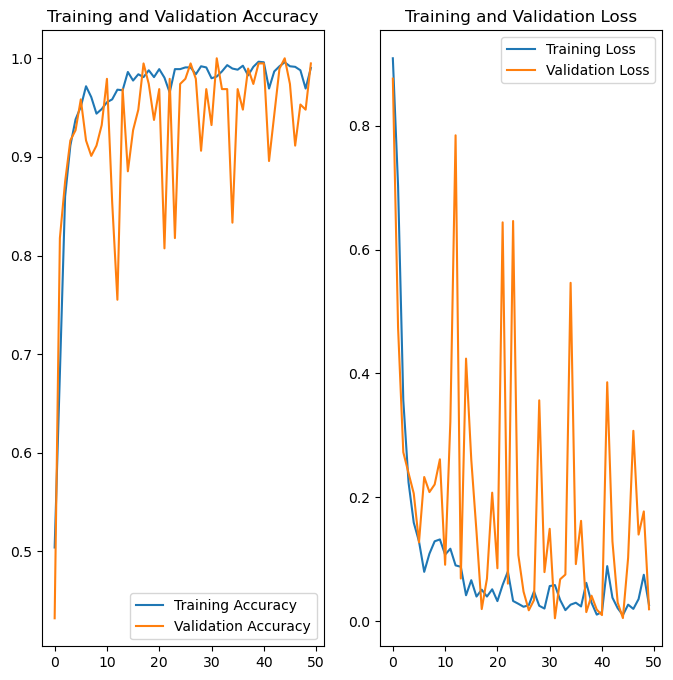

In [74]:
plt.figure(figsize=(8,8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label = 'Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label = 'Validation Accuracy')
plt.legend(loc = 'lower right')
plt.title('Training and Validation Accuracy')


plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label = 'Training Loss')
plt.plot(range(EPOCHS), val_loss, label = 'Validation Loss')
plt.legend(loc = 'upper right')
plt.title('Training and Validation Loss')

plt.show()

First Image to Predict
Actual label: Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step
Predicted label: Potato___Early_blight


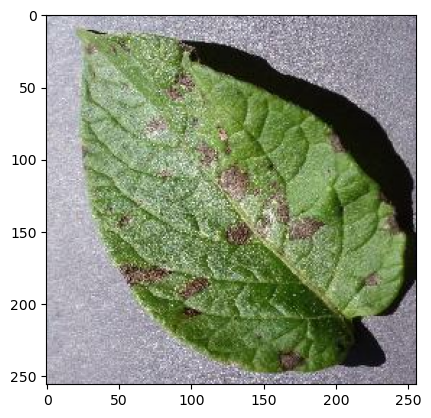

In [92]:
import numpy as np
for images_batch, labels_batch in test_ds.take(1):
    first_image = images_batch[0].numpy().astype("uint8")

    print("First Image to Predict")
    plt.imshow(first_image)
    print("Actual label:" ,class_names[labels_batch[0].numpy()])

    batch_prediction = model.predict(images_batch)
    print("Predicted label:",class_names[np.argmax(batch_prediction[0])])

In [94]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


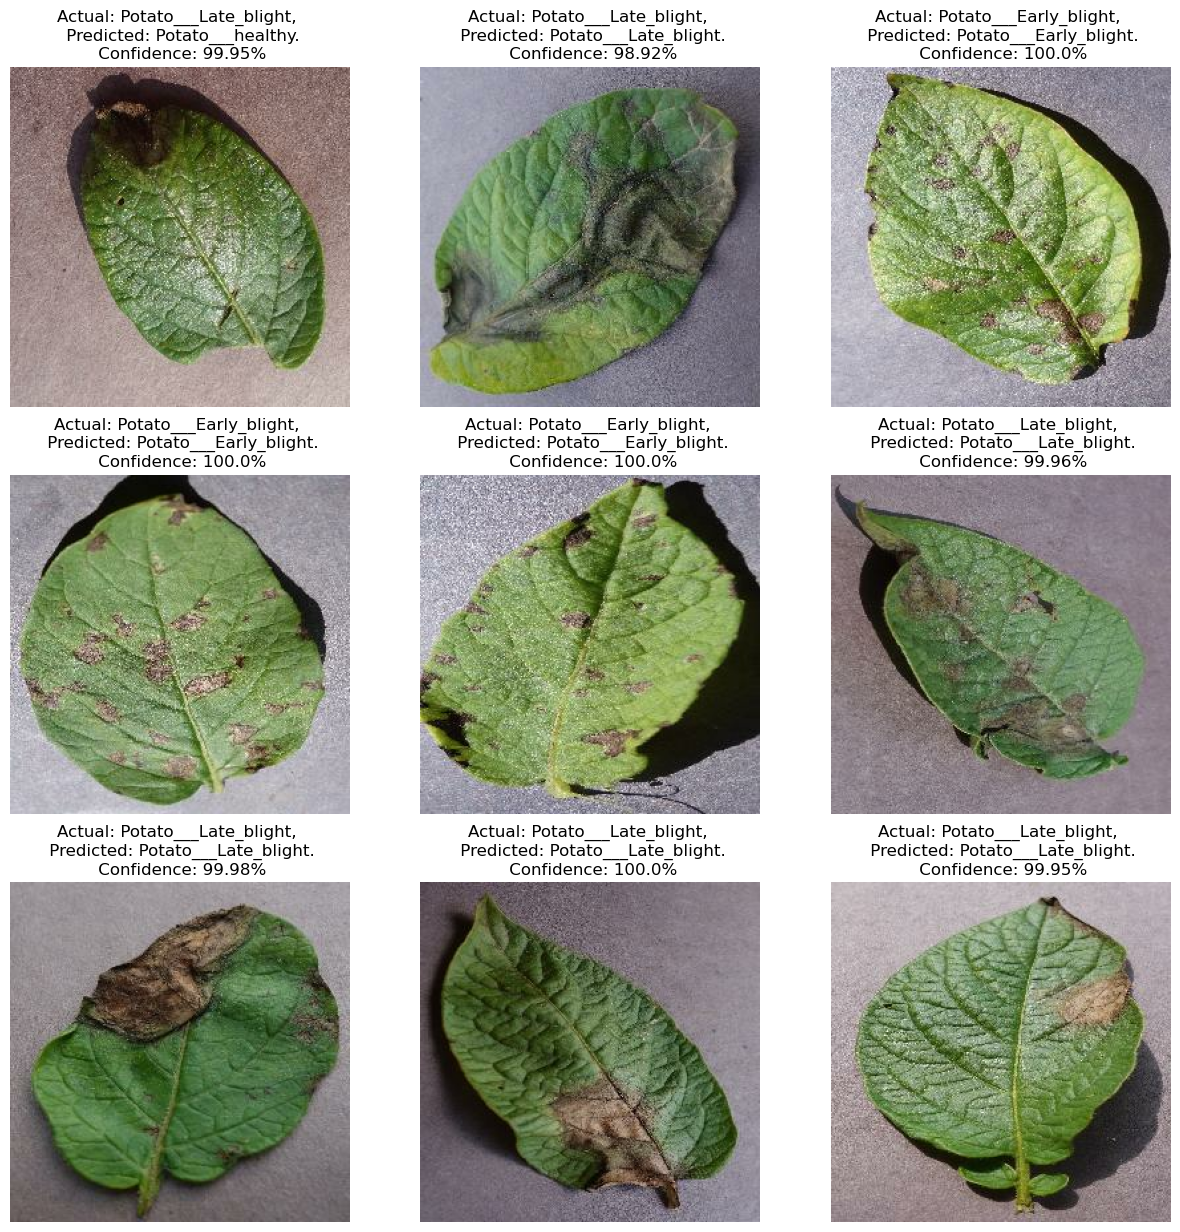

In [97]:
plt.figure(figsize = (15,15))
for images , labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class, confidence = predict(model, images[i].numpy())


        actual_class = class_names[labels[i]]
        plt.title(f"Actual: {actual_class}, \n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        plt.axis("off")

In [104]:
os.listdir("../models")

['1']

In [ ]:
import os 
model_version = max([int(i) for i in (os.listdir("../models")+[0])]) + 1
model.export(f"../models/{model_version}")

In [106]:
model_version = 1

model.export(f"../models/{model_version}")

INFO:tensorflow:Assets written to: ../models/1\assets


INFO:tensorflow:Assets written to: ../models/1\assets


Saved artifact at '../models/1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2279319889360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321845200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321895376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321897872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321894992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321895568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321899024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321898256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321899408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321899216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2279321899792: TensorSpec(shape=(), dty